# Book Market Analytics

**End-to-end data science project**: web scraping, cleaning, exploratory analysis, linear regression price prediction, and professional insights.

**Dataset source**: [books.toscrape.com](https://books.toscrape.com) (sandbox catalogue of 1 000 books across 50 genres)


## 1. Setup & Libraries

In [6]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import re
import time
from urllib.parse import urljoin
from concurrent.futures import ThreadPoolExecutor, as_completed
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print('Libraries loaded successfully.')


Libraries loaded successfully.


In [7]:
# --- Listing-page scraper ---
BASE = "https://books.toscrape.com/"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (compatible; DataScience500/1.0)"})

books = []
page = 1
while True:
    url = f"{BASE}catalogue/page-{page}.html"
    resp = session.get(url, timeout=15)
    if resp.status_code != 200:
        break
    soup = BeautifulSoup(resp.content, "html.parser")
    articles = soup.select("article.product_pod")
    if not articles:
        break
    for art in articles:
        title = art.h3.a.get("title", "").strip()
        price_text = art.select_one("p.price_color").get_text(strip=True)
        price = float(re.sub(r"[^\d.]", "", price_text))
        rating_class = art.select_one("p.star-rating")["class"]
        rating_word = [c for c in rating_class if c != "star-rating"][0]
        rating = RATING_MAP.get(rating_word, 0)
        avail_text = art.select_one("p.instock.availability").get_text(strip=True)
        in_stock = "In stock" in avail_text
        rel_link = art.h3.a.get("href", "")
        book_url = urljoin(url, rel_link)
        books.append({
            "title": title,
            "price_gbp": price,
            "rating_word": rating_word,
            "rating": rating,
            "availability": avail_text,
            "in_stock": in_stock,
            "url": book_url
        })
    print(f"Page {page}: collected {len(articles)} books (running total {len(books)})")
    if not soup.select_one("li.next a"):
        break
    page += 1
    time.sleep(0.25)

df_raw = pd.DataFrame(books)
print(f"\nRaw dataset shape: {df_raw.shape}")
df_raw.head()


Page 1: collected 20 books (running total 20)
Page 2: collected 20 books (running total 40)
Page 3: collected 20 books (running total 60)
Page 4: collected 20 books (running total 80)
Page 5: collected 20 books (running total 100)
Page 6: collected 20 books (running total 120)
Page 7: collected 20 books (running total 140)
Page 8: collected 20 books (running total 160)
Page 9: collected 20 books (running total 180)
Page 10: collected 20 books (running total 200)
Page 11: collected 20 books (running total 220)
Page 12: collected 20 books (running total 240)
Page 13: collected 20 books (running total 260)
Page 14: collected 20 books (running total 280)
Page 15: collected 20 books (running total 300)
Page 16: collected 20 books (running total 320)
Page 17: collected 20 books (running total 340)
Page 18: collected 20 books (running total 360)
Page 19: collected 20 books (running total 380)
Page 20: collected 20 books (running total 400)
Page 21: collected 20 books (running total 420)
Page 

,title,price_gbp,rating_word,rating,availability,in_stock,url
0,A Light in the Attic,51.77,Three,3,In stock,True,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,One,1,In stock,True,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,One,1,In stock,True,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,Four,4,In stock,True,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,True,https://books.toscrape.com/catalogue/sapiens-a...


In [8]:
# --- Enrich with category & exact stock quantity from product pages ---
def fetch_details(row):
    url = row["url"]
    try:
        resp = session.get(url, timeout=12)
        soup = BeautifulSoup(resp.content, "html.parser")
        crumbs = soup.select("ul.breadcrumb li a")
        category = crumbs[2].get_text(strip=True) if len(crumbs) >= 3 else "Unknown"
        avail = soup.select_one("p.instock.availability")
        avail_text = avail.get_text(strip=True) if avail else row["availability"]
        qty_match = re.search(r"(\d+)\s+available", avail_text)
        quantity = int(qty_match.group(1)) if qty_match else (1 if "In stock" in avail_text else 0)
        reviews = 0
        for tr in soup.select("table.table-striped tr"):
            if tr.th and "Number of reviews" in tr.th.get_text():
                reviews = int(tr.td.get_text(strip=True))
                break
        return {"url": url, "category": category, "stock_quantity": quantity,
                "num_reviews": reviews, "availability_detail": avail_text}
    except Exception as e:
        return {"url": url, "category": "Unknown", "stock_quantity": 0,
                "num_reviews": 0, "availability_detail": str(e)}

results = []
with ThreadPoolExecutor(max_workers=8) as ex:
    futures = [ex.submit(fetch_details, row) for _, row in df_raw.iterrows()]
    for i, fut in enumerate(as_completed(futures)):
        results.append(fut.result())
        if (i + 1) % 200 == 0:
            print(f"Enriched {i+1}/1000")

details_df = pd.DataFrame(results)
df = df_raw.merge(details_df, on="url", how="left")
print("Enriched shape:", df.shape)
df.head()


Enriched 200/1000
Enriched 400/1000
Enriched 600/1000
Enriched 800/1000
Enriched 1000/1000
Enriched shape: (1000, 11)


,title,price_gbp,rating_word,rating,availability,in_stock,url,category,stock_quantity,num_reviews,availability_detail
0,A Light in the Attic,51.77,Three,3,In stock,True,https://books.toscrape.com/catalogue/a-light-i...,Poetry,22,0,In stock (22 available)
1,Tipping the Velvet,53.74,One,1,In stock,True,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,20,0,In stock (20 available)
2,Soumission,50.10,One,1,In stock,True,https://books.toscrape.com/catalogue/soumissio...,Fiction,20,0,In stock (20 available)
3,Sharp Objects,47.82,Four,4,In stock,True,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,20,0,In stock (20 available)
4,Sapiens: A Brief History of Humankind,54.23,Five,5,In stock,True,https://books.toscrape.com/catalogue/sapiens-a...,History,20,0,In stock (20 available)


In [9]:
# Quick inspection
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nPrice stats:\n", df["price_gbp"].describe())
print("\nRating distribution:\n", df["rating"].value_counts().sort_index())
print("\nTop categories:\n", df["category"].value_counts().head(12))


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   title                1000 non-null   str    
 1   price_gbp            1000 non-null   float64
 2   rating_word          1000 non-null   str    
 3   rating               1000 non-null   int64  
 4   availability         1000 non-null   str    
 5   in_stock             1000 non-null   bool   
 6   url                  1000 non-null   str    
 7   category             1000 non-null   str    
 8   stock_quantity       1000 non-null   int64  
 9   num_reviews          1000 non-null   int64  
 10  availability_detail  1000 non-null   str    
dtypes: bool(1), float64(1), int64(3), str(6)
memory usage: 79.2 KB
None

Missing values:
 title                  0
price_gbp              0
rating_word            0
rating                 0
availability           0
in_stock               0
url           

In [10]:
# Cleaning decisions
df_clean = df.copy()

# Keep original quirky categories (they are real site labels) but create a grouped version
# for visualisation: lump very rare categories (< 10 books) into "Other"
cat_counts = df_clean["category"].value_counts()
rare = cat_counts[cat_counts < 10].index
df_clean["category_grouped"] = df_clean["category"].where(~df_clean["category"].isin(rare), "Other")

# Binary flag already present; ensure integer
df_clean["in_stock"] = df_clean["in_stock"].astype(int)

# Title length as a simple text-derived feature
df_clean["title_length"] = df_clean["title"].str.len()

# Log-price (optional, for later diagnostics)
df_clean["log_price"] = np.log1p(df_clean["price_gbp"])

# Final column order
cols = ["title", "category", "category_grouped", "price_gbp", "log_price",
        "rating", "rating_word", "stock_quantity", "in_stock",
        "num_reviews", "title_length", "url"]
df_clean = df_clean[cols]

print("Clean dataset shape:", df_clean.shape)
print(df_clean.dtypes)
df_clean.to_csv("books_clean.csv", index=False)
print("Saved books_clean.csv")
df_clean.head()


Clean dataset shape: (1000, 12)
title                   str
category                str
category_grouped        str
price_gbp           float64
log_price           float64
rating                int64
rating_word             str
stock_quantity        int64
in_stock              int64
num_reviews           int64
title_length          int64
url                     str
dtype: object
Saved books_clean.csv


,title,category,category_grouped,price_gbp,log_price,rating,rating_word,stock_quantity,in_stock,num_reviews,title_length,url
0,A Light in the Attic,Poetry,Poetry,51.77,3.965943,3,Three,22,1,0,20,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Historical Fiction,Historical Fiction,53.74,4.002595,1,One,20,1,0,18,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Fiction,Fiction,50.10,3.933784,1,One,20,1,0,10,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Mystery,Mystery,47.82,3.888140,4,Four,20,1,0,13,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,History,History,54.23,4.011506,5,Five,20,1,0,37,https://books.toscrape.com/catalogue/sapiens-a...


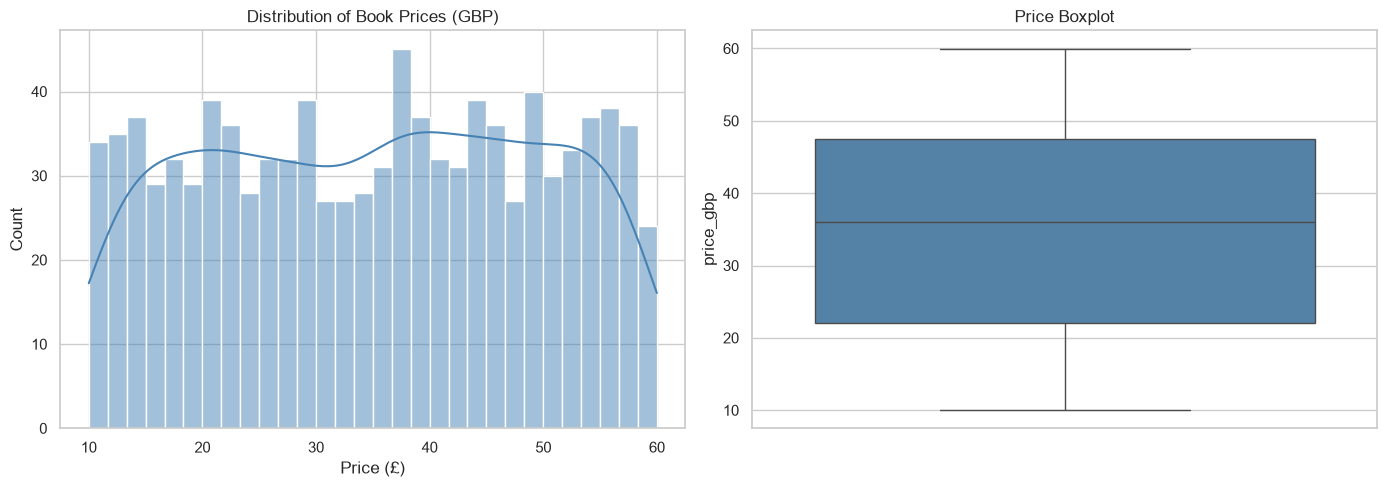

Mean price: £35.07 | Median: £35.98


In [11]:
# 4.1 Price distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["price_gbp"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of Book Prices (GBP)")
ax[0].set_xlabel("Price (£)")
sns.boxplot(y=df_clean["price_gbp"], ax=ax[1], color="steelblue")
ax[1].set_title("Price Boxplot")
plt.tight_layout()
plt.savefig("fig_price_dist.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Mean price: £{df_clean['price_gbp'].mean():.2f} | Median: £{df_clean['price_gbp'].median():.2f}")


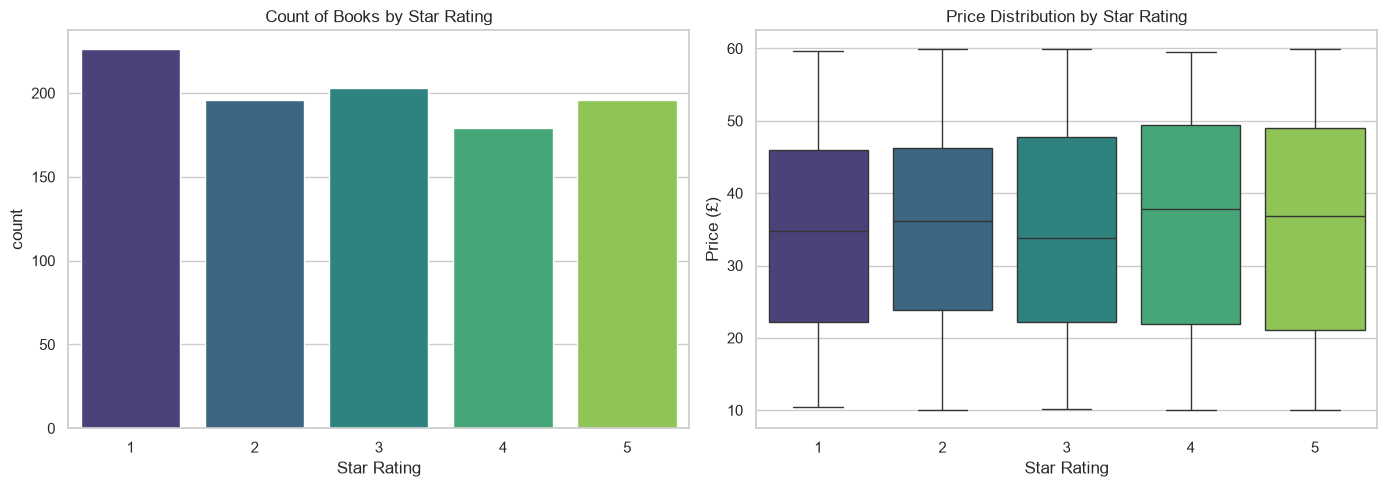

         mean  median  count
rating                      
1       34.56   34.77    226
2       34.81   36.22    196
3       34.69   33.78    203
4       36.09   37.80    179
5       35.37   36.90    196


In [12]:
# 4.2 Rating distribution & price by rating
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x="rating", data=df_clean, ax=ax[0], palette="viridis")
ax[0].set_title("Count of Books by Star Rating")
ax[0].set_xlabel("Star Rating")
sns.boxplot(x="rating", y="price_gbp", data=df_clean, ax=ax[1], palette="viridis")
ax[1].set_title("Price Distribution by Star Rating")
ax[1].set_xlabel("Star Rating")
ax[1].set_ylabel("Price (£)")
plt.tight_layout()
plt.savefig("fig_rating_price.png", dpi=120, bbox_inches="tight")
plt.show()

print(df_clean.groupby("rating")["price_gbp"].agg(["mean", "median", "count"]).round(2))


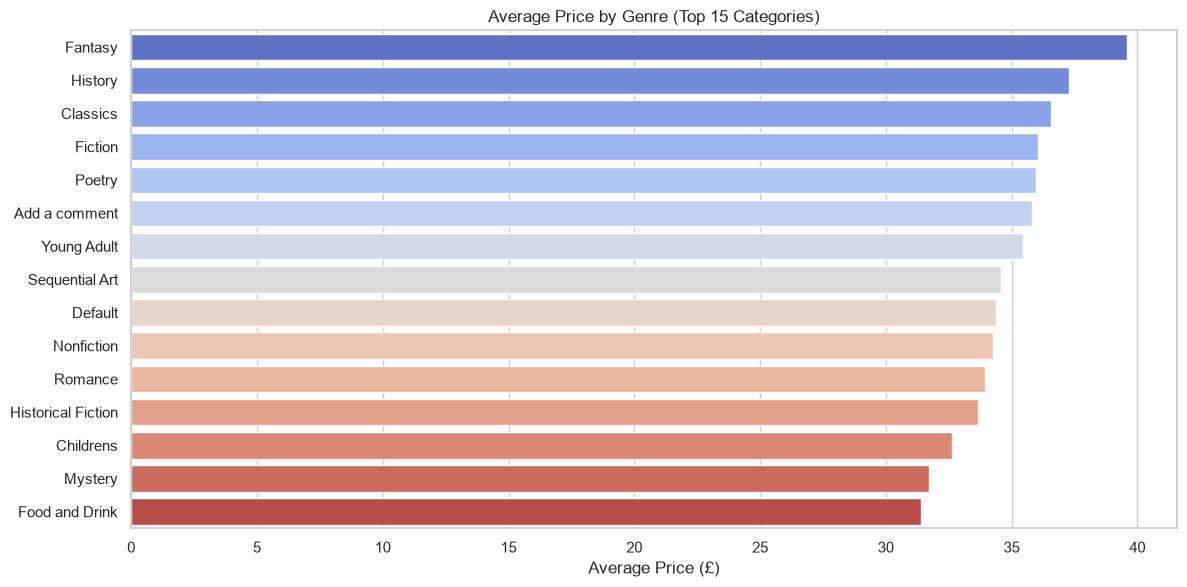

category
Fantasy               39.59
History               37.29
Classics              36.55
Fiction               36.07
Poetry                35.97
Add a comment         35.80
Young Adult           35.45
Sequential Art        34.57
Default               34.39
Nonfiction            34.26
Romance               33.93
Historical Fiction    33.64
Childrens             32.64
Mystery               31.72
Food and Drink        31.41
Name: price_gbp, dtype: float64


In [13]:
# 4.3 Average price by genre (top 15 categories)
top_cats = df_clean["category"].value_counts().head(15).index
cat_price = (df_clean[df_clean["category"].isin(top_cats)]
             .groupby("category")["price_gbp"]
             .mean()
             .sort_values(ascending=False))

plt.figure(figsize=(12, 6))
sns.barplot(x=cat_price.values, y=cat_price.index, palette="coolwarm")
plt.title("Average Price by Genre (Top 15 Categories)")
plt.xlabel("Average Price (£)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("fig_genre_price.png", dpi=120, bbox_inches="tight")
plt.show()
print(cat_price.round(2))


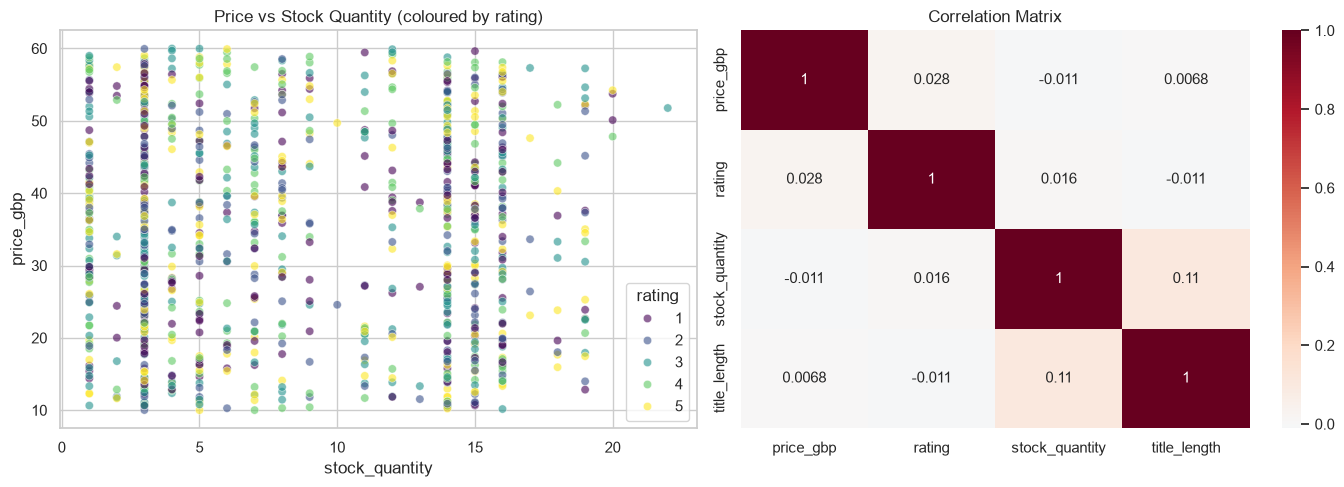

In [14]:
# 4.4 Stock quantity vs price + correlation
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x="stock_quantity", y="price_gbp", hue="rating",
                data=df_clean, ax=ax[0], palette="viridis", alpha=0.6)
ax[0].set_title("Price vs Stock Quantity (coloured by rating)")
sns.heatmap(df_clean[["price_gbp", "rating", "stock_quantity", "title_length"]].corr(),
            annot=True, cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.savefig("fig_corr_stock.png", dpi=120, bbox_inches="tight")
plt.show()


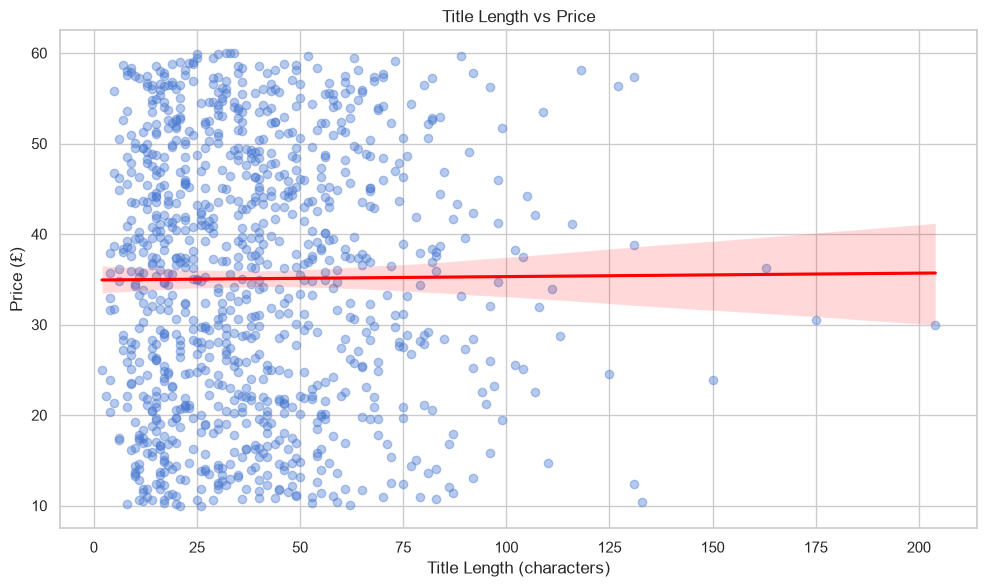

In [15]:
# 4.5 Title length vs price
sns.regplot(x="title_length", y="price_gbp", data=df_clean,
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("Title Length vs Price")
plt.xlabel("Title Length (characters)")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.savefig("fig_title_len.png", dpi=120, bbox_inches="tight")
plt.show()


In [16]:
# Prepare modelling matrix
cat_dummies = pd.get_dummies(df_clean["category_grouped"], prefix="cat", drop_first=True)
X = pd.concat([
    df_clean[["rating", "stock_quantity", "title_length"]],
    cat_dummies
], axis=1)
y = df_clean["price_gbp"]

print("Feature matrix shape:", X.shape)
print("Features:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n=== Model Performance (Test Set) ===")
print(f"RMSE : £{rmse:.2f}")
print(f"MAE  : £{mae:.2f}")
print(f"R²   : {r2:.4f}")


Feature matrix shape: (1000, 28)
Features: ['rating', 'stock_quantity', 'title_length', 'cat_Business', 'cat_Childrens', 'cat_Classics', 'cat_Default', 'cat_Fantasy', 'cat_Fiction', 'cat_Food and Drink', 'cat_Historical Fiction', 'cat_History', 'cat_Horror', 'cat_Humor', 'cat_Music', 'cat_Mystery', 'cat_Nonfiction', 'cat_Other', 'cat_Philosophy', 'cat_Poetry', 'cat_Romance', 'cat_Science', 'cat_Science Fiction', 'cat_Sequential Art', 'cat_Thriller', 'cat_Travel', 'cat_Womens Fiction', 'cat_Young Adult']

=== Model Performance (Test Set) ===
RMSE : £14.94
MAE  : £12.91
R²   : -0.0619


Intercept (baseline price): £35.39

Top coefficients (by absolute magnitude):
               feature  coefficient
           cat_Mystery    -7.054095
          cat_Business    -6.408919
         cat_Childrens    -6.062221
          cat_Thriller    -5.109761
   cat_Science Fiction    -4.985321
             cat_Humor     4.882775
    cat_Food and Drink    -4.370432
        cat_Philosophy    -4.254751
cat_Historical Fiction    -3.992210
        cat_Nonfiction    -3.722946
    cat_Womens Fiction    -3.280937
           cat_Science    -3.271433
            cat_Travel     2.848025
           cat_Default    -2.550925
           cat_Romance    -2.354251


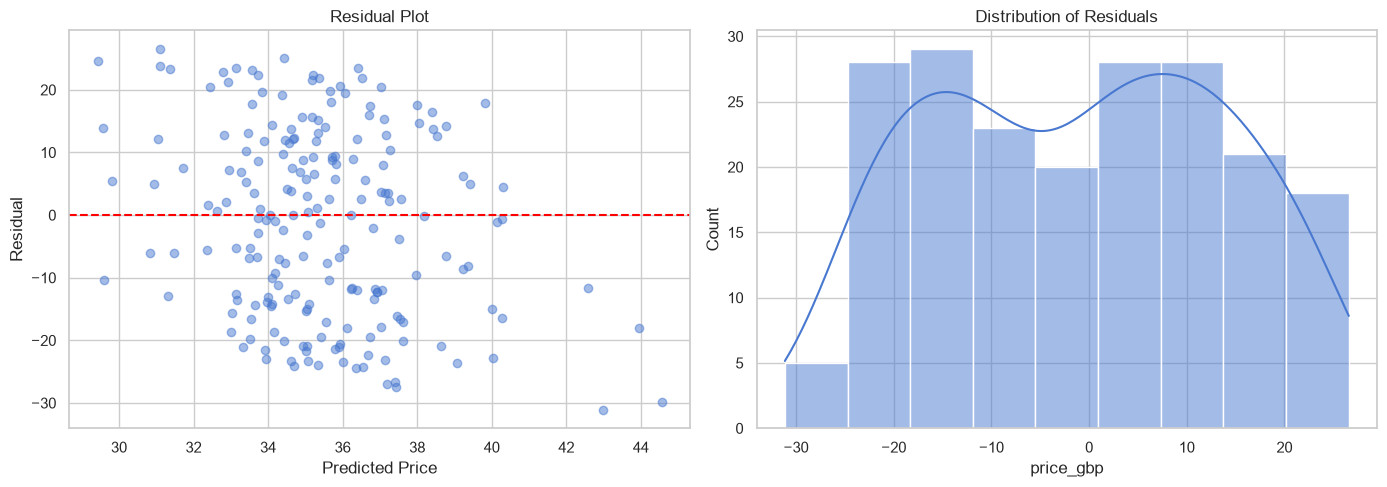

In [28]:
# Coefficients interpretation
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_
}).sort_values("coefficient", key=abs, ascending=False)

print("Intercept (baseline price): £{:.2f}".format(model.intercept_))
print("\nTop coefficients (by absolute magnitude):")
print(coef_df.head(15).to_string(index=False))

# Residual plot
residuals = y_test - y_pred
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_pred, residuals, alpha=0.5)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xlabel("Predicted Price")
ax[0].set_ylabel("Residual")
ax[0].set_title("Residual Plot")
sns.histplot(residuals, kde=True, ax=ax[1])
ax[1].set_title("Distribution of Residuals")
plt.tight_layout()
plt.savefig("fig_residuals.png", dpi=120, bbox_inches="tight")
plt.show()


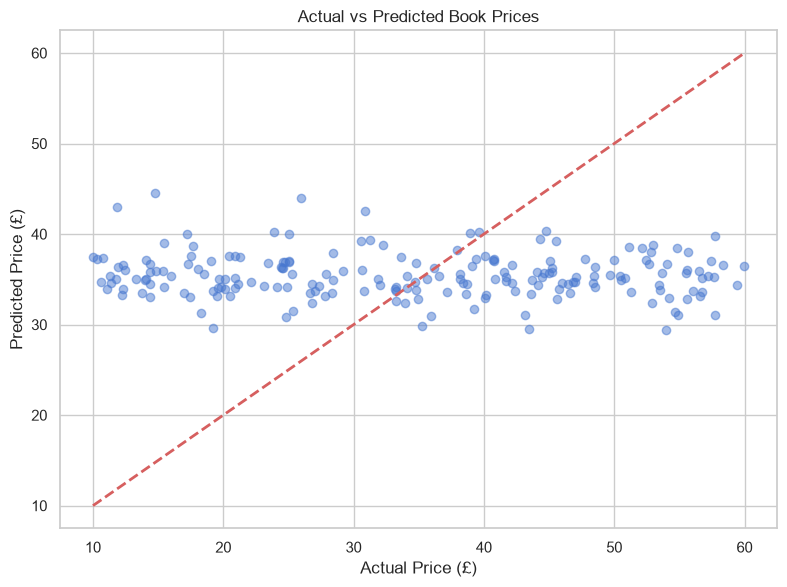

In [29]:
# Predicted vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price (£)")
plt.title("Actual vs Predicted Book Prices")
plt.tight_layout()
plt.savefig("fig_pred_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()
